Q14. Feature Importance

Using the Breast Cancer Wisconsin dataset, train a Decision Tree classifier and display a
bar chart of its top five feature importances. 

In [47]:
from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import shap

In [48]:
cancer = load_breast_cancer()

In [49]:
x=cancer.data
y=cancer.target

In [50]:
x_train, x_test, y_train, _y_test = train_test_split(
    x,y, test_size=0.2, random_state=42
)

In [51]:
model = DecisionTreeClassifier()
model.fit(x_train, y_train)

DecisionTreeClassifier()

In [52]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(x_test)

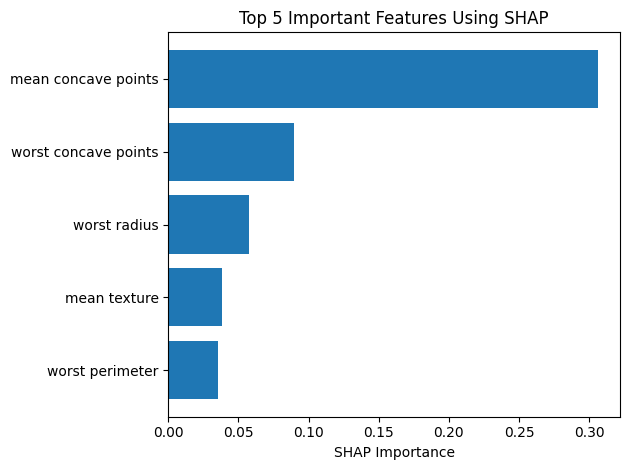

In [46]:
# Calculate importance of each feature
importance = np.abs(shap_values[:, :, 1]).mean(axis=0)

# Select top 5 features
top5 = np.argsort(importance)[-5:]

# Display graph
plt.barh(cancer.feature_names[top5], importance[top5])
plt.xlabel("SHAP Importance")
plt.title("Top 5 Important Features Using SHAP")
plt.tight_layout()
plt.show()